# CSC 349 HW4: Heart Disease

I used the UCI Cleveland dataset to compare an SVC and a Decision Tree. A target of 0 means no heart disease. A target of 1 means heart disease is present.

**Status:** Checked locally. The Google Colab run is still needed.

[Dataset source](https://archive.ics.uci.edu/dataset/45/heart+disease)

## Task 1: Load the data

This code loads the Cleveland data from UCI into a Pandas DataFrame. It adds column names and changes the original diagnosis into two groups: no disease and disease. It also checks the dataset size and prints the number of patients in each group.

In [1]:
import io, zipfile, hashlib, json, platform
from urllib.request import urlopen
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

SEED = 42
DATA_URL = 'https://archive.ics.uci.edu/static/public/45/heart+disease.zip'
archive_bytes = urlopen(DATA_URL, timeout=60).read()
archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()
columns = ['age','sex','cp','trestbps','chol','fbs','restecg',
           'thalach','exang','oldpeak','slope','ca','thal','diagnosis']
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    member = next(n for n in archive.namelist()
                  if n.split('/')[-1] == 'processed.cleveland.data')
    raw = pd.read_csv(archive.open(member), names=columns,
                      dtype=str, keep_default_na=False)
assert raw.shape == (303, 14), raw.shape
diagnosis = pd.to_numeric(raw['diagnosis'], errors='raise')
assert diagnosis.isin([0,1,2,3,4]).all()
df = raw.copy()
df['target'] = (diagnosis > 0).astype(int)
print('Python:', platform.python_version(), 'pandas:', pd.__version__,
      'scikit-learn:', sklearn.__version__)
print('Archive SHA-256:', archive_sha256)
print('Rows and original columns:', raw.shape)
print('Binary target counts (0=no disease, 1=disease):')
print(df['target'].value_counts().sort_index())

Python: 3.12.14 pandas: 2.2.3 scikit-learn: 1.8.0
Archive SHA-256: b17cd273da9ce1caa4710fce80227ea454d4dbf9fcbc8e6a9121672751563adc
Rows and original columns: (303, 14)
Binary target counts (0=no disease, 1=disease):
target
0    164
1    139
Name: count, dtype: int64


## Task 2: Check the data

I use `head()`, `info()`, and `describe()` to check the rows, column types, and values. I also count the category values. Some categories use numbers as labels, so I treat them as categories instead of measurements.

In [2]:
numerical = ['age','trestbps','chol','thalach','oldpeak']
categorical = ['sex','cp','fbs','restecg','exang','slope','ca','thal']
features = numerical + categorical
display(df.head())
df.info()
display(df.describe(include='all'))
inspection = df[features].apply(lambda s: pd.to_numeric(s.str.strip(), errors='coerce'))
print('Continuous measurements:')
display(inspection[numerical].describe())
print('Categorical code frequencies:')
for column in categorical:
    print(column, df[column].value_counts(dropna=False).sort_index().to_dict())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        303 non-null    object
 1   sex        303 non-null    object
 2   cp         303 non-null    object
 3   trestbps   303 non-null    object
 4   chol       303 non-null    object
 5   fbs        303 non-null    object
 6   restecg    303 non-null    object
 7   thalach    303 non-null    object
 8   exang      303 non-null    object
 9   oldpeak    303 non-null    object
 10  slope      303 non-null    object
 11  ca         303 non-null    object
 12  thal       303 non-null    object
 13  diagnosis  303 non-null    object
 14  target     303 non-null    int64 
dtypes: int64(1), object(14)
memory usage: 35.6+ KB
Continuous measurements:
Categorical code frequencies:
sex {'0.0': 97, '1.0': 206}
cp {'1.0': 23, '2.0': 50, '3.0': 86, '4.0': 144}
fbs {'0.0': 258, '1.0': 45}
restecg {'0.0': 151,

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,diagnosis,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,diagnosis,target
count,303,303,303,303,303,303,303,303,303,303,303,303,303,303,303.000000
unique,41,2,4,50,152,2,3,91,2,40,3,5,4,5,NaN
top,58.0,1.0,4.0,120.0,204.0,0.0,0.0,162.0,0.0,0.0,1.0,0.0,3.0,0,NaN
freq,19,206,144,37,6,258,151,11,204,99,142,176,166,164,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.458746
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.499120
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000


,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,131.689769,246.693069,149.607261,1.039604
std,9.038662,17.599748,51.776918,22.875003,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.500000,0.000000
50%,56.000000,130.000000,241.000000,153.000000,0.800000
75%,61.000000,140.000000,275.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


## Task 3: Handle missing values

This code checks for missing values, including hidden ones such as `?` and blank spaces. I use the median for missing numerical values and the most common value for categories. I split the data first so the test data does not affect these choices.

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

tokens = {'?', '', 'na', 'n/a', 'nan', 'null', 'none'}
text = raw.apply(lambda s: s.str.strip())
implicit_mask = text.apply(lambda s: s.str.lower().isin(tokens))
missing_audit = pd.DataFrame({'actual_nulls': raw.isna().sum(),
                             'implicit_placeholders': implicit_mask.sum()})
display(missing_audit)
cleaned = text.mask(implicit_mask).apply(pd.to_numeric, errors='raise')
X = cleaned[features].copy()
y = df['target'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
numeric_imputer = SimpleImputer(strategy='median')
category_imputer = SimpleImputer(strategy='most_frequent')
numeric_preview = numeric_imputer.fit_transform(X_train[numerical])
category_preview = category_imputer.fit_transform(X_train[categorical])
assert not np.isnan(numeric_preview).any()
assert not np.isnan(category_preview).any()
print('Training shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Training numerical medians:', dict(zip(numerical, numeric_imputer.statistics_)))
print('Training categorical modes:', dict(zip(categorical, category_imputer.statistics_)))
print('Training numerical skewness:')
display(X_train[numerical].skew())

Training shape: (242, 13) Test shape: (61, 13)
Training numerical medians: {'age': np.float64(56.0), 'trestbps': np.float64(130.0), 'chol': np.float64(244.5), 'thalach': np.float64(153.5), 'oldpeak': np.float64(0.8)}
Training categorical modes: {'sex': np.float64(1.0), 'cp': np.float64(4.0), 'fbs': np.float64(0.0), 'restecg': np.float64(0.0), 'exang': np.float64(0.0), 'slope': np.float64(1.0), 'ca': np.float64(0.0), 'thal': np.float64(3.0)}
Training numerical skewness:


,actual_nulls,implicit_placeholders
age,0,0
sex,0,0
cp,0,0
trestbps,0,0
chol,0,0
fbs,0,0
restecg,0,0
thalach,0,0
exang,0,0
oldpeak,0,0


age        -0.172393
trestbps    0.725117
chol        1.219506
thalach    -0.575394
oldpeak     1.465713
dtype: float64

## Task 4: Build the pipeline

The pipeline fills missing values, scales numerical columns with `StandardScaler`, and encodes categories with `OneHotEncoder`. Scaling helps the SVC compare features with different units. Keeping these steps in the pipeline prevents the test data from affecting training.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.base import clone

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numerical),
    ('cat', categorical_pipeline, categorical)])
def make_model(estimator):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', estimator)])
preview_preprocessor = clone(preprocessor)
train_transformed = preview_preprocessor.fit_transform(X_train)
test_transformed = preview_preprocessor.transform(X_test)
assert np.isfinite(train_transformed).all() and np.isfinite(test_transformed).all()
print('Transformed train/test shapes:', train_transformed.shape, test_transformed.shape)
print('Output features:', preview_preprocessor.get_feature_names_out().tolist())

Transformed train/test shapes: (242, 28) (61, 28)
Output features: ['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'cat__sex_0.0', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__fbs_0.0', 'cat__fbs_1.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__exang_0.0', 'cat__exang_1.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__ca_0.0', 'cat__ca_1.0', 'cat__ca_2.0', 'cat__ca_3.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0']


## Task 5: Train the SVC

I train an SVC with an RBF kernel and `probability=True`. The confusion matrix shows correct and incorrect predictions. The classification report shows precision, recall, and F1. The ROC curve and AUC show how well the model separates the two groups.

Baseline SVC
              precision    recall  f1-score   support

  No disease     0.9333    0.8485    0.8889        33
     Disease     0.8387    0.9286    0.8814        28

    accuracy                         0.8852        61
   macro avg     0.8860    0.8885    0.8851        61
weighted avg     0.8899    0.8852    0.8854        61

ROC-AUC: 0.9643


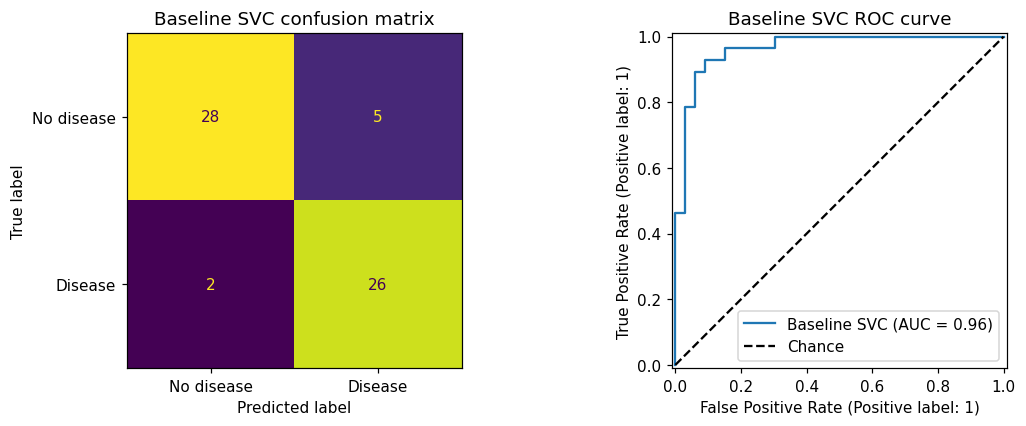

In [5]:
from sklearn.svm import SVC
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay,
    classification_report, confusion_matrix, roc_auc_score, accuracy_score,
    precision_score, recall_score, f1_score)
results = {}
def evaluate_model(name, model):
    predictions = model.predict(X_test)
    class_one = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_test)[:, class_one]
    cm = confusion_matrix(y_test, predictions, labels=[0,1])
    result = {'accuracy': accuracy_score(y_test, predictions),
              'precision': precision_score(y_test, predictions, zero_division=0),
              'recall': recall_score(y_test, predictions, zero_division=0),
              'f1': f1_score(y_test, predictions, zero_division=0),
              'roc_auc': roc_auc_score(y_test, probabilities),
              'confusion_matrix': cm.tolist()}
    results[name] = result
    print(name)
    print(classification_report(y_test, predictions, labels=[0,1],
          target_names=['No disease','Disease'], digits=4, zero_division=0))
    print('ROC-AUC:', round(result['roc_auc'], 4))
    fig, axes = plt.subplots(1,2, figsize=(11,4))
    ConfusionMatrixDisplay(cm, display_labels=['No disease','Disease']).plot(
        ax=axes[0], colorbar=False)
    axes[0].set_title(name + ' confusion matrix')
    RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1], name=name)
    axes[1].plot([0,1],[0,1], 'k--', label='Chance')
    axes[1].set_title(name + ' ROC curve')
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    return result
svc = make_model(SVC(kernel='rbf', probability=True, C=1.0,
                     gamma='scale', random_state=SEED))
svc.fit(X_train, y_train)
svc_metrics = evaluate_model('Baseline SVC', svc)

## Task 6: Train the Decision Tree

I train a Decision Tree using the same pipeline and train/test split. I check it with the same metrics as the SVC so the comparison is fair. I also check its training accuracy to see whether it may be overfitting.

Decision Tree
              precision    recall  f1-score   support

  No disease     0.8148    0.6667    0.7333        33
     Disease     0.6765    0.8214    0.7419        28

    accuracy                         0.7377        61
   macro avg     0.7456    0.7440    0.7376        61
weighted avg     0.7513    0.7377    0.7373        61

ROC-AUC: 0.744
Tree training accuracy: 1.0
Tree depth: 9 Leaves: 47


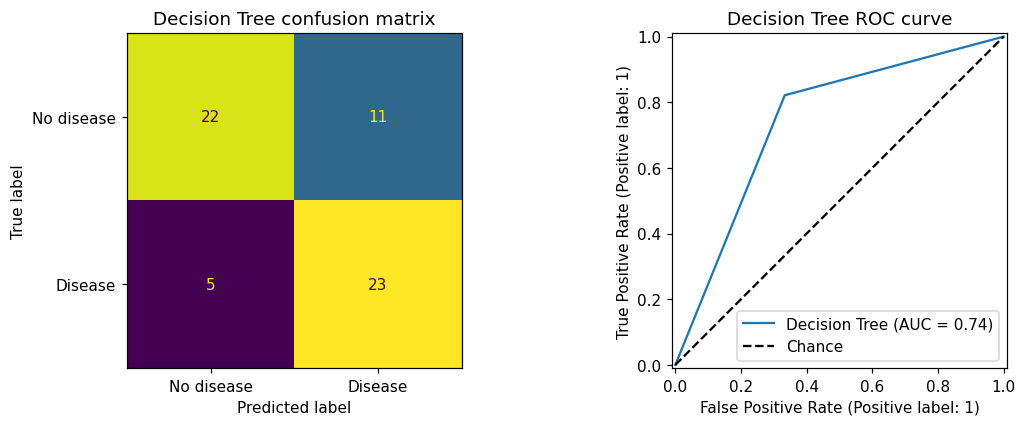

,accuracy,precision,recall,f1,roc_auc
Baseline SVC,0.885246,0.83871,0.928571,0.881356,0.964286
Decision Tree,0.737705,0.676471,0.821429,0.741935,0.744048


In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
tree = make_model(DecisionTreeClassifier(random_state=SEED))
tree.fit(X_train, y_train)
tree_metrics = evaluate_model('Decision Tree', tree)
print('Tree training accuracy:', accuracy_score(y_train, tree.predict(X_train)))
print('Tree depth:', tree.named_steps['model'].get_depth(),
      'Leaves:', tree.named_steps['model'].get_n_leaves())
display(pd.DataFrame(results).T.drop(columns=['confusion_matrix']))

## Task 7: Tune the SVC

I use `GridSearchCV` to try different values of `C` and `gamma`. It compares them using five folds of the training data and chooses the best average ROC-AUC. I then check the selected model on the test data.

Best parameters: {'model__C': 100, 'model__gamma': 0.001}
Best mean cross-validation ROC-AUC: 0.9026992331340157
Tuned SVC
              precision    recall  f1-score   support

  No disease     0.9000    0.8182    0.8571        33
     Disease     0.8065    0.8929    0.8475        28

    accuracy                         0.8525        61
   macro avg     0.8532    0.8555    0.8523        61
weighted avg     0.8571    0.8525    0.8527        61

ROC-AUC: 0.9481


,param_model__C,param_model__gamma,mean_train_score,mean_test_score,std_test_score,rank_test_score
16,100.0,0.001,0.930600,0.902699,0.019676,1
11,10.0,0.001,0.918899,0.898163,0.022470,2
12,10.0,0.01,0.940039,0.896836,0.018361,3
7,1.0,0.01,0.920273,0.895708,0.025355,4
5,1.0,scale,0.965161,0.888373,0.024024,5
8,1.0,0.1,0.967331,0.886651,0.025187,6
0,0.1,scale,0.912672,0.885524,0.032081,7
3,0.1,0.1,0.913684,0.884840,0.031319,8
2,0.1,0.01,0.890404,0.882105,0.035150,9
1,0.1,0.001,0.888770,0.877994,0.035774,10


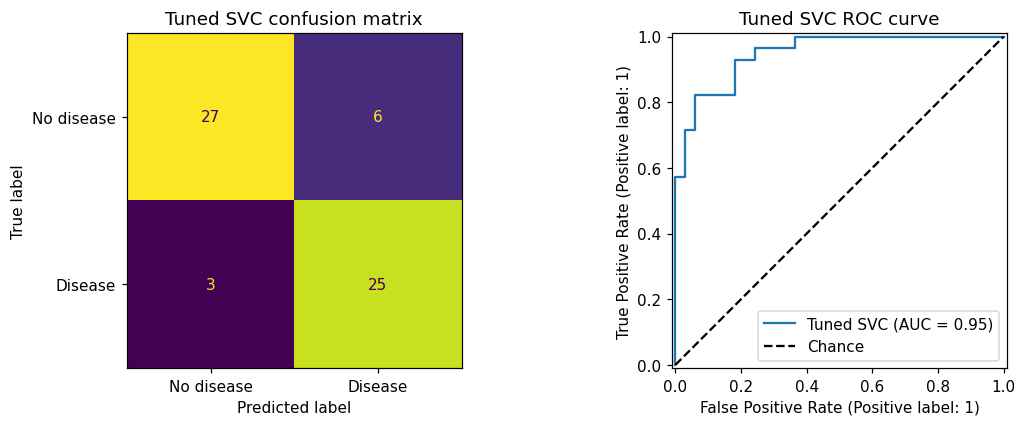

,accuracy,precision,recall,f1,roc_auc
Baseline SVC,0.885246,0.83871,0.928571,0.881356,0.964286
Decision Tree,0.737705,0.676471,0.821429,0.741935,0.744048
Tuned SVC,0.852459,0.806452,0.892857,0.847458,0.948052


In [7]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grid = {'model__C': [0.1,1,10,100],
        'model__gamma': ['scale',0.001,0.01,0.1,1.0]}
search = GridSearchCV(make_model(SVC(kernel='rbf', probability=True, random_state=SEED)),
    grid, scoring='roc_auc', cv=cv, n_jobs=1, return_train_score=True, refit=True)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
display(cv_results[['param_model__C','param_model__gamma',
    'mean_train_score','mean_test_score','std_test_score','rank_test_score']])
print('Best parameters:', search.best_params_)
print('Best mean cross-validation ROC-AUC:', search.best_score_)
tuned_metrics = evaluate_model('Tuned SVC', search.best_estimator_)
display(pd.DataFrame(results).T.drop(columns=['confusion_matrix']))

## Task 8: Look at the tree

I rank the features by their importance to the Decision Tree and show the first three levels of the tree. I combine the encoded categories under their original feature names. These results show what the model used most, not what causes heart disease. I also save the results for the analysis.

Encoded feature importances:
Original clinical feature importances:
All eight tasks completed. Results saved to heart_disease_results.json.


,importance
cat__thal_3.0,0.292921
cat__cp_4.0,0.119427
num__chol,0.110055
num__oldpeak,0.107935
cat__ca_0.0,0.097622
num__age,0.096128
cat__sex_0.0,0.033909
num__trestbps,0.027639
cat__cp_3.0,0.019416
num__thalach,0.018673


,importance
thal,0.292921
cp,0.144734
ca,0.111887
chol,0.110055
oldpeak,0.107935
age,0.096128
sex,0.033909
trestbps,0.027639
thalach,0.018673
fbs,0.016444


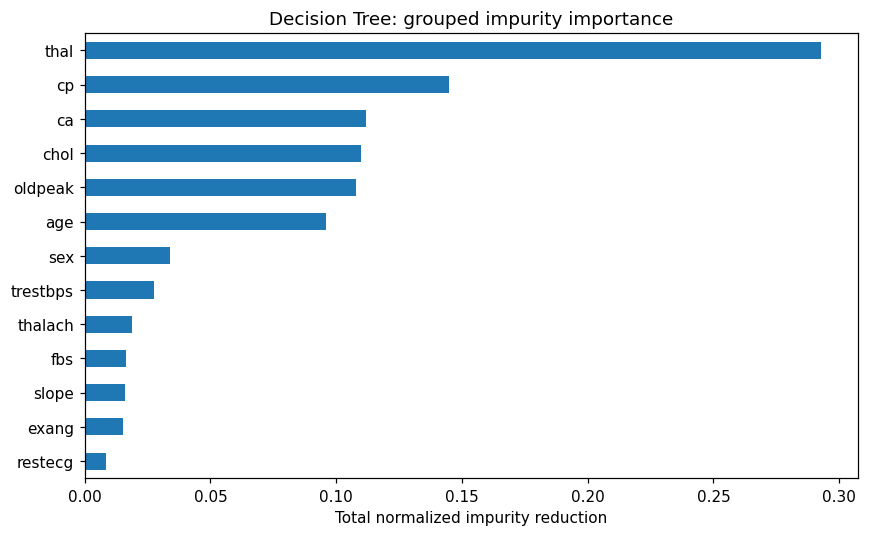

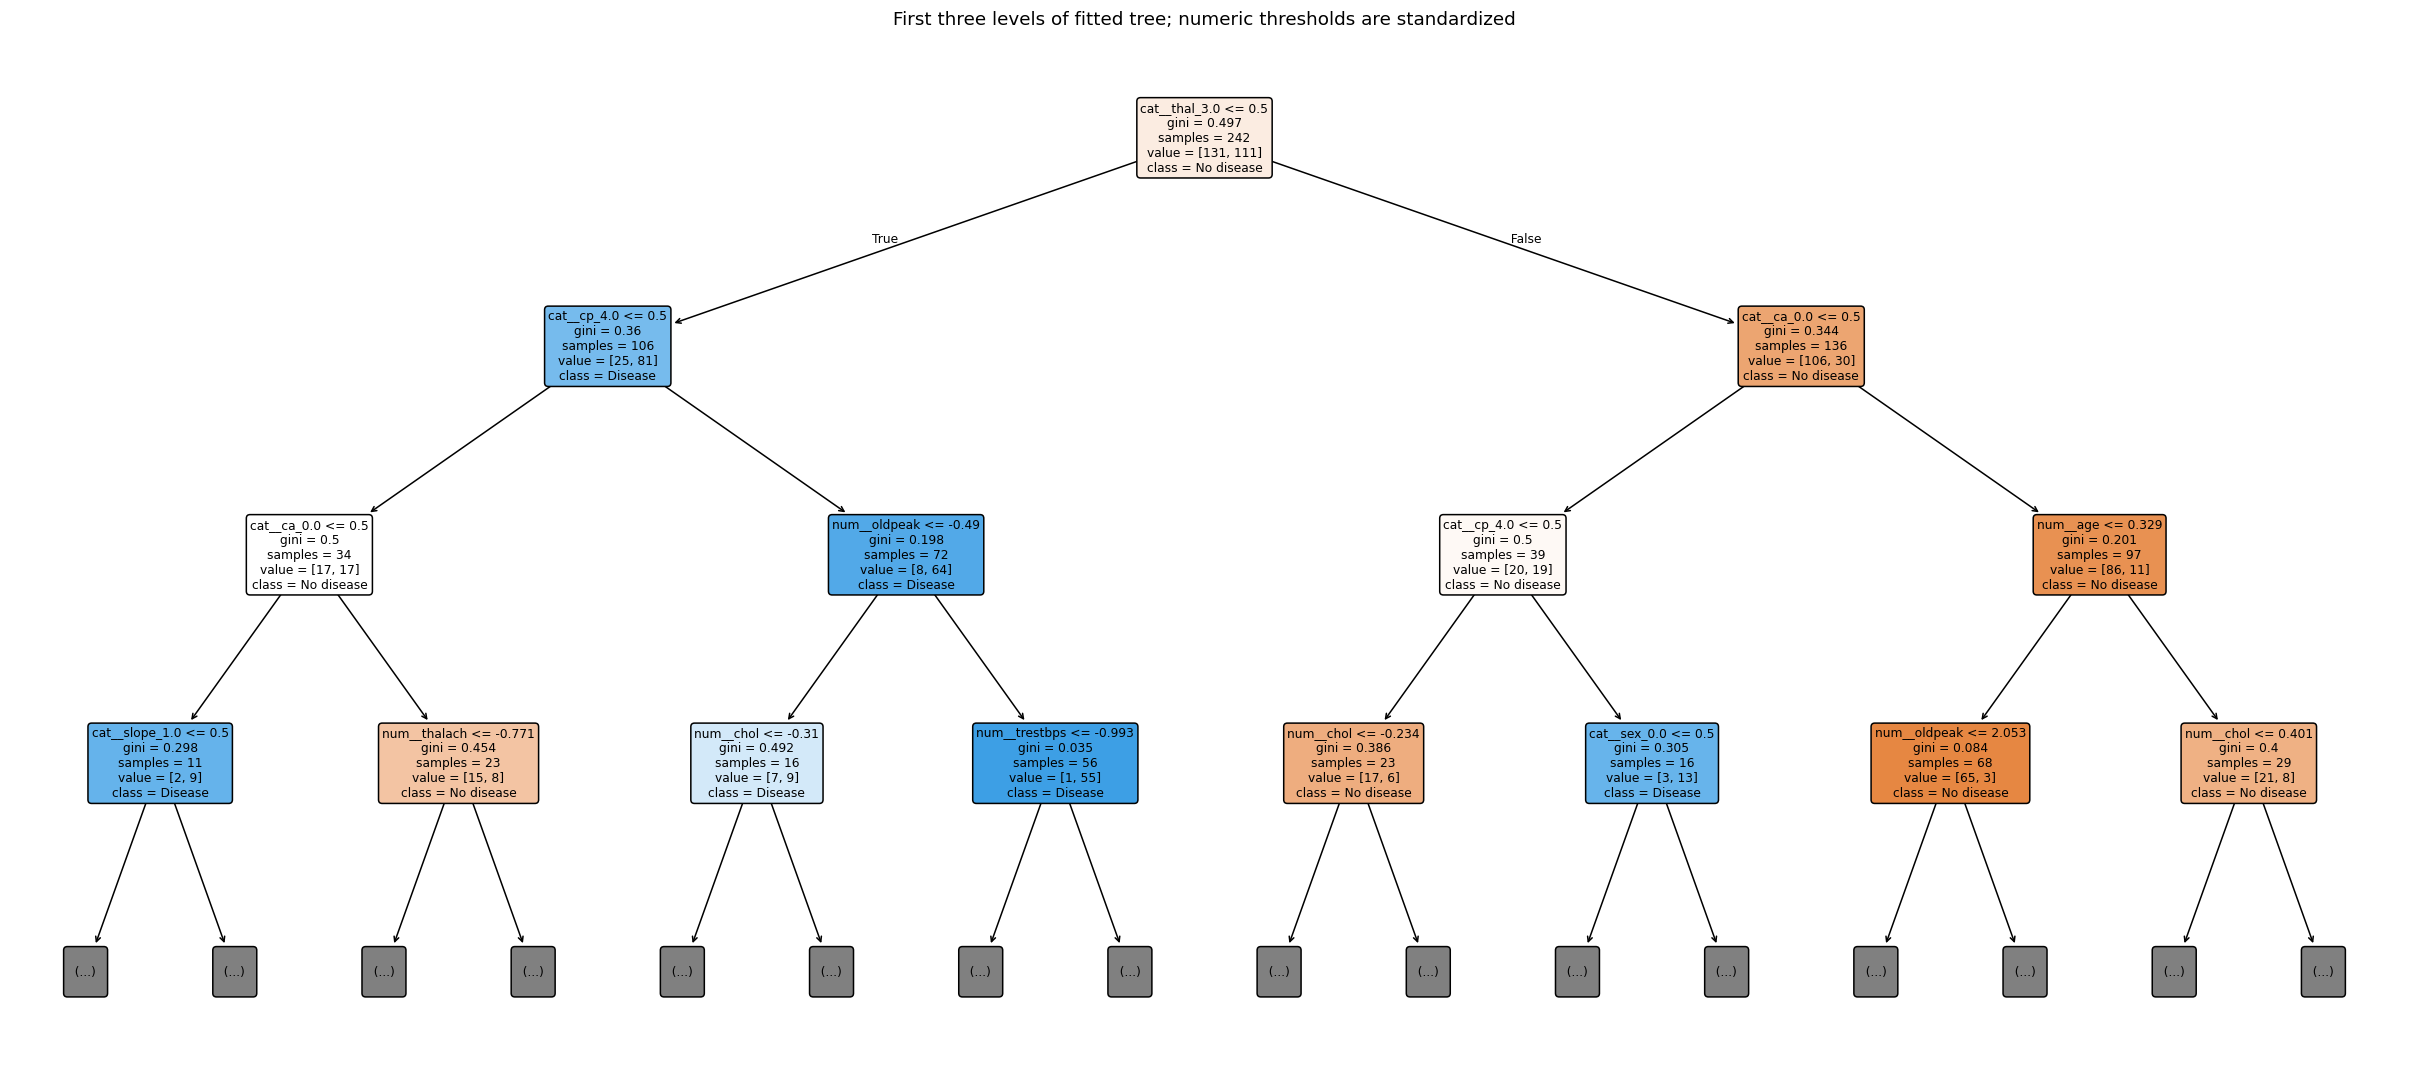

In [8]:
names = tree.named_steps['preprocess'].get_feature_names_out()
importances = tree.named_steps['model'].feature_importances_
encoded_importance = pd.Series(importances, index=names).sort_values(ascending=False)
mapping = dict(zip(names[:len(numerical)], numerical))
position = len(numerical)
encoder = tree.named_steps['preprocess'].named_transformers_['cat'].named_steps['encoder']
for column, categories in zip(categorical, encoder.categories_):
    for _ in categories:
        mapping[names[position]] = column
        position += 1
grouped_importance = pd.Series(importances, index=[mapping[n] for n in names]).groupby(level=0).sum().sort_values(ascending=False)
assert position == len(names)
assert np.isclose(importances.sum(), 1)
assert all(sum(map(sum, r['confusion_matrix'])) == len(y_test) for r in results.values())
print('Encoded feature importances:')
display(encoded_importance.to_frame('importance'))
print('Original clinical feature importances:')
display(grouped_importance.to_frame('importance'))
grouped_importance.sort_values().plot.barh(figsize=(8,5), title='Decision Tree: grouped impurity importance')
plt.xlabel('Total normalized impurity reduction')
plt.tight_layout(); plt.show()
plt.figure(figsize=(22,10))
plot_tree(tree.named_steps['model'], feature_names=names.tolist(),
          class_names=['No disease','Disease'], filled=True, max_depth=3,
          rounded=True, fontsize=8)
plt.title('First three levels of fitted tree; numeric thresholds are standardized')
plt.tight_layout(); plt.show()
summary = {'dataset': 'UCI processed Cleveland', 'archive_sha256': archive_sha256,
    'sklearn_version': sklearn.__version__, 'random_state': SEED,
    'n_train': len(y_train), 'n_test': len(y_test),
    'target_counts': {str(k):int(v) for k,v in y.value_counts().items()},
    'missing_counts': {k:int(v) for k,v in X.isna().sum().items()},
    'metrics': results, 'best_params': search.best_params_,
    'best_cv_auc': float(search.best_score_),
    'best_cv_std': float(search.cv_results_['std_test_score'][search.best_index_]),
    'grouped_importance': grouped_importance.to_dict(),
    'encoded_importance': encoded_importance.to_dict(),
    'tree_train_accuracy': float(accuracy_score(y_train, tree.predict(X_train)))}
Path('heart_disease_results.json').write_text(json.dumps(summary, indent=2))
print('All eight tasks completed. Results saved to heart_disease_results.json.')